# STATE Codex R2 — Perturbation modality

All custom calculations are executable inline. Run the six sections in order. Model evaluation uses the pinned public STATE releases. Use Python 3.11 with numpy 1.26.4, pandas 2.2.2, scipy 1.13.1, pyarrow 16.1.0, matplotlib 3.9.4, h5py 3.11.0, fsspec, aiohttp, IPython and ipykernel. `STATE_R2_INPUTS` may point at a verified raw-input cache.

## 1. Data source and acquisition

The URLs, sizes and SHA-256 values below identify the public input objects.

In [1]:
from pathlib import Path
import os,json,hashlib,time,platform,urllib.request,urllib.parse,ast,tomllib,re,zipfile,itertools
os.environ['OMP_NUM_THREADS']='1';os.environ['OPENBLAS_NUM_THREADS']='1';os.environ['MKL_NUM_THREADS']='1'
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import fsspec,h5py
from scipy.stats import spearmanr,pearsonr,rankdata
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image
START=time.time()
DATA=Path(os.environ.get('STATE_R2_INPUTS','state_r2_inputs')).resolve(); DATA.mkdir(parents=True,exist_ok=True)
ROOT=Path('test-05_outputs').resolve();ROOT.mkdir(parents=True,exist_ok=True)
CELLS={'C32':'C32','HOP62':'HOP62','HepG2/C3A':'HepG2-C3A','Hs 766T':'Hs 766T','PANC-1':'PANC-1'}
CTX=['k562','jurkat','hepg2','rpe1']

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'path': 'ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 528013,
  'sha256': 'eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3'},
 {'path': 'ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 568100,
  'sha256': '372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317'},
 {'path': 'ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 509894,
  'sha256': '9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a'},
 {'path': 'ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 535692,
  'sha256': 'ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa'},
 {'path': 'ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 538095,
  'sha256': '8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821'},
 {'path': 'ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 582103,
  'sha256': '3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098'},
 {'path': 'ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 506756,
  'sha256': '0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604'},
 {'path': 'ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 575323,
  'sha256': 'c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 281263,
  'sha256': '9fee724f7d5dc46a3e0061e264347ce4c8c5c29b6c0dac2dc67303bcae25894a'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 269030,
  'sha256': '646052bbdb9844e1a2b94f19c095d0f5a07db9529010f41252c61ba228544d56'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 287583,
  'sha256': '9106d01893815fbf77d85f4e2351da8a607adedc74edb62cc452c110812b09a2'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/Hs%20766T_results.csv',
  'bytes': 277100,
  'sha256': '80c38255fdce0444457f909d7ef9c2186a82c5476550bfe82604bd48896aae72'},
 {'path': 'ST-SE-Tahoe/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/fewshot/state_generalization_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 273025,
  'sha256': '5a40d67c26a428487d3b0f602b5b7a69006b5c4595eaaf0ffb5f44eaf5160239'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv',
  'bytes': 468674,
  'sha256': 'cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv',
  'bytes': 463111,
  'sha256': 'dedd141ec8fdff513a19cb46f3bb95b76372b117935620b02f50f2f8e339d33d'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 473841,
  'sha256': 'a3c6d89ea4f07e395aac68db6a36222ced41f6acea648e8e5d008cd5912cf0fb'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs '
          '766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs%20766T_results.csv',
  'bytes': 468068,
  'sha256': '4904a9d8a3ed52a2cccd9de85cd0eeec0277bcc07d184eefb8096395719a2746'},
 {'path': 'ST-SE-Tahoe/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 464280,
  'sha256': '8483133246cf1dba89c76a94f8a407757f4714bff5c9534f66890fbfe3d7ec03'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080'},
 {'path': 'ST-HVG-Tahoe/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332'}]


In [3]:
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(8388608),b''):h.update(b)
    return h.hexdigest()
def checked(root,rel):
    x=next(x for x in SOURCES if x['path']==rel);p=DATA/rel
    if not p.exists() or p.stat().st_size!=x['bytes'] or sha(p)!=x['sha256']:raise ValueError('Input checksum mismatch: '+rel)
    return p
for x in SOURCES:
    p=DATA/x['path'];p.parent.mkdir(parents=True,exist_ok=True)
    if not p.exists():
        temp=p.with_suffix(p.suffix+'.part')
        req=urllib.request.Request(x['url'],headers={'User-Agent':'STATE-notebook/1.0'})
        with urllib.request.urlopen(req,timeout=180) as source,temp.open('wb') as target:
            while b:=source.read(8388608):target.write(b)
        if temp.stat().st_size!=x['bytes'] or sha(temp)!=x['sha256']:raise ValueError('Downloaded source identity mismatch: '+x['path'])
        temp.replace(p)
    checked(ROOT,x['path'])
print('Verified public input files:',len(SOURCES))


Verified public input files: 23


## 2. Data processing

In [4]:
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()

def dump(path, obj):
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(obj, indent=2, default=lambda x: x.item() if isinstance(x, np.generic) else str(x), allow_nan=False) + '\n')

def zscore(x):
    x = np.asarray(x, dtype=float)
    s = x.std(ddof=0)
    if not s > 0:
        raise ValueError('Constant predictor')
    return (x - x.mean()) / s

def fisher(x):
    return np.arctanh(np.clip(np.asarray(x, float), -1 + 1e-07, 1 - 1e-07))

def cluster_fit(d, y, x, cluster, adjust=(), fixed=(), cluster_fixed=False, draws=10000, seed=20260715):
    cols = [y, x, cluster, *adjust, *fixed]
    d = d.dropna(subset=cols).copy()
    X = [np.ones(len(d)), zscore(d[x])]
    names = ['intercept', x]
    for c in adjust:
        v = np.asarray(d[c], float)
        if np.std(v) > 0:
            X.append(zscore(v))
            names.append(c)
    for c in fixed:
        for val in sorted(d[c].unique())[1:]:
            X.append((d[c] == val).astype(float).values)
            names.append(f'{c}={val}')
    X = np.column_stack(X)
    Y = d[y].to_numpy(float)
    groups = sorted(d[cluster].unique())
    codes = pd.Categorical(d[cluster], categories=groups).codes
    if cluster_fixed:
        for j in range(len(groups)):
            sel = codes == j
            X[sel] -= X[sel].mean(axis=0)
            Y[sel] -= Y[sel].mean()
        X = X[:, 1:]
        names = names[1:]
        axis_idx = 0
    else:
        axis_idx = 1
    gxx = np.zeros((len(groups), X.shape[1], X.shape[1]))
    gxy = np.zeros((len(groups), X.shape[1]))
    for j in range(len(groups)):
        sel = codes == j
        gxx[j] = X[sel].T @ X[sel]
        gxy[j] = X[sel].T @ Y[sel]
    coefficient = np.linalg.lstsq(X, Y, rcond=None)[0]
    rng = np.random.default_rng(seed)
    boot = []
    for start in range(0, draws, 100):
        n = min(100, draws - start)
        w = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=n)
        xx = np.einsum('bg,gij->bij', w, gxx)
        xy = w @ gxy
        for a, b in zip(xx, xy):
            boot.append(np.linalg.lstsq(a, b, rcond=None)[0][axis_idx])
    return (dict(n=len(d), clusters=len(groups), coefficient=float(coefficient[axis_idx]), ci95=np.quantile(boot, [0.025, 0.975]).tolist(), draws=draws, seed=seed, design_columns=names, cluster_fixed_effect=cluster_fixed, axis_standardization='population SD on all analyzed rows', coefficients=dict(zip(names, coefficient))), np.asarray(boot))

def curve(d, level, score, cluster, draws=10000, seed=20260715):
    groups = sorted(d[cluster].unique())
    levels = sorted(d[level].unique())
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)), size=draws)
    rows = []
    boot = {}
    for v in levels:
        q = d[d[level] == v]
        g = q.groupby(cluster)[score].agg(['sum', 'count']).reindex(groups, fill_value=0)
        b = w @ g['sum'].values / (w @ g['count'].values)
        boot[str(v)] = b
        rows.append(dict(level=v, n=len(q), clusters=q[cluster].nunique(), mean=q[score].mean(), ci_low=np.quantile(b, 0.025), ci_high=np.quantile(b, 0.975)))
    return (pd.DataFrame(rows), boot)

In [5]:
assignments=[]
for s in SOURCES:
    model=s['path'].split('/')[0];dataset='Replogle' if 'Replogle' in model else 'Tahoe'
    assignments.append({'source':s['path'],'dataset':dataset,'modality':'genetic CRISPRi' if dataset=='Replogle' else 'chemical drug','representation':'SE' if '-SE-' in model else 'HVG','released_rows':len(pd.read_csv(DATA/s['path']))})
assignments=pd.DataFrame(assignments);display(assignments)

,source,dataset,modality,representation,released_rows
0,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k5...,Replogle,genetic CRISPRi,SE,1383
1,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/...,Replogle,genetic CRISPRi,SE,1537
2,ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/h...,Replogle,genetic CRISPRi,SE,1340
3,ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rp...,Replogle,genetic CRISPRi,SE,1499
4,ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k...,Replogle,genetic CRISPRi,HVG,1383
5,ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt...,Replogle,genetic CRISPRi,HVG,1537
6,ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/...,Replogle,genetic CRISPRi,HVG,1340
7,ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/r...,Replogle,genetic CRISPRi,HVG,1499
8,ST-SE-Tahoe/fewshot/state_generalization_X_sta...,Tahoe,chemical drug,SE,735
9,ST-SE-Tahoe/fewshot/state_generalization_X_sta...,Tahoe,chemical drug,SE,735


## 3. Axis definition and level construction

In [6]:
assignments['dataset_indicator']=assignments.dataset.eq('Tahoe').astype(int)
assignments['modality_indicator']=assignments.modality.eq('chemical drug').astype(int)
X=np.column_stack([np.ones(len(assignments)),assignments.dataset_indicator,assignments.modality_indicator])
rank=int(np.linalg.matrix_rank(X))
print('Design columns:',X.shape[1],'Rank:',rank)
print('Modality and dataset indicators equal:',np.array_equal(X[:,1],X[:,2]))

Design columns: 3 Rank: 2
Modality and dataset indicators equal: True


## 4. Model results and released scores

The public releases contain both outcome tables, but modality is identical to dataset membership. Adding outcomes cannot resolve that design confounding, so no modality effect is fitted.

## 5. Curves and controls

source_tables  released_rows
dataset  modality        representation                              
Replogle genetic CRISPRi HVG                         4           5759
                         SE                          4           5759
Tahoe    chemical drug   HVG                         5           5684
                         SE                         10           9358

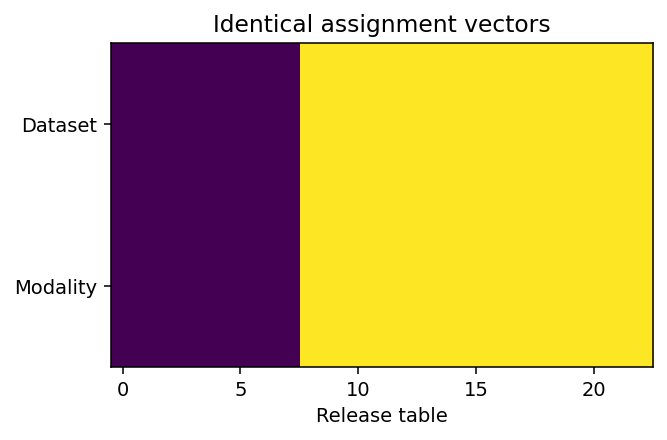

In [7]:
display(assignments.groupby(['dataset','modality','representation']).agg(source_tables=('source','size'),released_rows=('released_rows','sum')))
fig,ax=plt.subplots(figsize=(5,3));ax.imshow(X[:,1:].T,aspect='auto');ax.set_yticks([0,1],['Dataset','Modality']);ax.set(xlabel='Release table',title='Identical assignment vectors');display_figure(fig);plt.close(fig)

## 6. What the agent decided, and why

Reject the modality comparison as nonidentifiable: genetic perturbations occur only in Replogle and chemical perturbations only in Tahoe. The two assignment columns are exactly collinear.

In [8]:
record={'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'sources':SOURCES,'custom_external_code_used':False,'model_inference_performed':False}
(ROOT/'execution_record.json').write_text(json.dumps(record,indent=2))
print('Completed:',ROOT)

Completed: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/state/state-codex-r2/test-05_outputs
